# Análisis de Gestión de Incidentes y Cumplimiento de SLA

## Objetivo

Analizar los datos del proceso de gestión de incidentes para evaluar el desempeño operativo, el cumplimiento de los Acuerdos de Nivel de Servicio (SLA) y la eficiencia del proceso de soporte.

## Conjunto de Datos

**Registro Enriquecido del Proceso de Gestión de Incidentes (Incident Management Process Enriched Event Log)**

- Registros: 141.712
- Variables: 36
- Incidentes únicos: 24.918

## Alcance del Proyecto

Este proyecto se centra en:

- Análisis del ciclo de vida de los incidentes.
- Seguimiento del cumplimiento de los SLA.
- Evaluación de los tiempos de resolución.
- Análisis del desempeño operativo.
- Medición de la eficiencia del proceso de soporte.

## Descripción General de los Datos

El conjunto de datos contiene registros de eventos generados durante el ciclo de vida de un incidente. Un mismo incidente puede estar asociado a múltiples registros, lo que permite realizar análisis orientados al proceso, incluyendo cambios de estado, reasignaciones, resoluciones y cierres de incidentes.

# Estructura del Proyecto

1. Importación de librerías
2. Limpieza de datos
3. Resumen de la evaluación inicial del conjunto de datos limpio
4. Ventana temporal de análisis e inicio del EDA
5. Preguntas de negocio a resolver

   5.1. ¿Los incidentes son reasignados frecuentemente?

   5.2. ¿Los incidentes son reabiertos frecuentemente?

   5.3. ¿Los incidentes requieren múltiples actualizaciones durante su ciclo de vida?

   5.4. ¿Cómo fue el comportamiento mensual del ingreso de los casos?

   5.5. ¿Cómo fue la distribución de los SLA en los diferentes trimestres y cuál fue su nivel de cumplimiento?

   5.6. ¿Cómo evolucionó la creación de incidentes a lo largo del tiempo?

   5.7. ¿Cuál es el estado actual de los incidentes?

   5.8. ¿Cuál es la relación entre impacto, urgencia y prioridad? 

6. Hallazgos principales
7. Limitaciones del análisis
8. Exportación del conjunto de datos para Power BI

# 1. Importación de librerías

In [1]:
# ==================================================
# 📚 IMPORTACIÓN DE LIBRERÍAS
# ==================================================

# 📂🧹🔍📊 Librerías básicas para exploración y análisis

# Librería para trabajar con DataFrames
import pandas as pd
pd.set_option('display.max_columns', None)

# Librería para cálculos numéricos y matrices
import numpy as np

# Librerías para visualización
import matplotlib.pyplot as plt      # Más personalizable
import seaborn as sns                # Más moderna y estética



In [2]:
# Carga y copia del conjunto de datos

df = pd.read_csv(
    "../Data/Raw/incident+management+process+enriched+event+log.zip"
)
df_cl = df.copy()


# 2. Limpieza de datos

In [3]:
# Reemplazar los valores desconocidos representados mediante "?"
# por valores nulos reconocidos por Pandas.

df_cl = df_cl.replace("?", np.nan)


# Convertir las columnas temporales al tipo de dato datetime.

df_cl["opened_at"] = pd.to_datetime(df_cl["opened_at"],format="%d/%m/%Y %H:%M")
df_cl["sys_created_at"] = pd.to_datetime(df_cl["sys_created_at"],format="%d/%m/%Y %H:%M")
df_cl["sys_updated_at"] = pd.to_datetime(df_cl["sys_updated_at"],format="%d/%m/%Y %H:%M")
df_cl["resolved_at"] = pd.to_datetime(df_cl["resolved_at"],format="%d/%m/%Y %H:%M")
df_cl["closed_at"] = pd.to_datetime(df_cl["closed_at"],format="%d/%m/%Y %H:%M")


# Convertir variables categóricas para optimizar el consumo de memoria
# y representar adecuadamente atributos discretos relacionados con
# el proceso de gestión de incidentes.

df_cl["incident_state"] = df_cl["incident_state"].astype("category")
df_cl["contact_type"] = df_cl["contact_type"].astype("category")
df_cl["impact"] = df_cl["impact"].astype("category")
df_cl["urgency"] = df_cl["urgency"].astype("category")
df_cl["priority"] = df_cl["priority"].astype("category")
df_cl["notify"] = df_cl["notify"].astype("category")


# Convertir campos de referencia con alta cantidad de valores faltantes
# en variables booleanas.
# Para efectos del análisis resulta más relevante identificar si existe
# una relación asociada (problema, cambio, proveedor o causa) que conservar
# el identificador específico de dicha relación.

df_cl["problem_id"] = df_cl["problem_id"].notna()
df_cl["rfc"] = df_cl["rfc"].notna()
df_cl["vendor"] = df_cl["vendor"].notna()
df_cl["caused_by"] = df_cl["caused_by"].notna()


# Eliminar columnas redundantes o de bajo valor analítico

# Eliminar la marca temporal de creación, ya que el conjunto de datos
# ya contiene la columna 'opened_at', que proporciona información
# equivalente para el análisis de creación de incidentes.

df_cl = df_cl.drop (columns=["sys_created_at"])

# Eliminar la columna asociada al creador del incidente.
# Al eliminar la fecha de creación por redundancia,
# esta variable deja de aportar valor analítico.
df_cl = df_cl.drop (columns=["sys_created_by"])

# Eliminar el identificador del elemento de configuración (CMDB),
# ya que no contribuye a los objetivos analíticos definidos para
# este proyecto.
df_cl = df_cl.drop (columns=["cmdb_ci"])

In [4]:
#Valida datos limpios
print("Dimensiones del conjunto limpio:", df_cl.shape)
print("Registros de eventos duplicados:", df_cl.duplicated().sum())

display(
    df_cl.dtypes.to_frame(name="tipo_de_dato")
)

display(
    df_cl.isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)


Dimensiones del conjunto limpio: (141712, 33)
Registros de eventos duplicados: 0


,tipo_de_dato
number,str
incident_state,category
active,bool
reassignment_count,int64
reopen_count,int64
sys_mod_count,int64
made_sla,bool
caller_id,str
opened_by,str
opened_at,datetime64[us]


u_symptom           32964
assigned_to         27496
assignment_group    14213
opened_by            4835
resolved_at          3141
closed_code           714
resolved_by           226
subcategory           111
category               78
location               76
dtype: int64

# 3. Resumen de la evaluación inicial del conjunto de datos limpio

El conjunto de datos limpio contiene:

- 141.712 registros
- 33 variables

Todas las variables fueron revisadas y clasificadas de acuerdo con su relevancia para el negocio, calidad de los datos y utilidad analítica.

El diccionario de datos detallado fue documentado por separado.

### Resumen de la clasificación de variables

| Categoría | Número de Variables |
|----------|----------|
| Identificadores | 12 |
| Campos de Fecha | 4 |
| Variables Categóricas | 6 |
| Variables Booleanas | 8 |
| Métricas Operativas | 3 |

### Principales observaciones

- Varios identificadores aparecen repetidos debido a que múltiples registros pertenecen al mismo incidente.
- Las variables **prioridad**, **impacto** y **urgencia** constituyen atributos fundamentales para el análisis operativo.
- Algunos campos de referencia presentan una alta proporción de valores nulos.
- Se identificaron campos temporales redundantes que posteriormente fueron considerados durante la fase de limpieza.


### Documentación de referencia

Se realizó una revisión detallada de las 36 variables orignales del conjunto de datos. El diccionario de datos completo fue documentado por separado y se encuentra disponible dentro de la carpeta Data/Processed archivo excel "Diccionario de datos.xlsx" como soporte metodológico para las decisiones de limpieza, transformación y análisis realizadas en este proyecto


# 4. Ventana temporal de análisis es inicio del EDA


El conjunto de datos abarca desde febrero de 2016 hasta febrero de 2017.

Sin embargo, ambos extremos del periodo presentan trimestres incompletos:

- El primer trimestre de 2016 está representado parcialmente.
- El primer trimestre de 2017 también está incompleto.

Con el objetivo de garantizar consistencia en los indicadores temporales y evitar sesgos derivados de periodos parciales, el análisis se centrará en el segundo, tercer y cuarto trimestre de 2016.

Esto permite trabajar con una ventana temporal estable compuesta por trimestres completos para el análisis operativo y de procesos.



In [5]:
#Definicion de intervalo de analisis

df_analysis = df_cl[
    (df_cl["opened_at"] >= "2016-04-01") &
    (df_cl["opened_at"] < "2017-01-01")
]

df_analysis_q2 = df_cl[
    (df_cl["opened_at"] >= "2016-04-01") &
    (df_cl["opened_at"] < "2016-07-01")
]

df_analysis_q3 = df_cl[
    (df_cl["opened_at"] >= "2016-07-01") &
    (df_cl["opened_at"] < "2016-10-01")
]

df_analysis_q4 = df_cl[
    (df_cl["opened_at"] >= "2016-10-01") &
    (df_cl["opened_at"] < "2017-01-01")
]

#Lo anterior acota el numero de casos de 24.918 a 15.567
#Tambien reduce los datos de 141.712 a 81529

total_number = df_analysis["number"].nunique()
total_analysis = df_analysis["number"].count()

print("Total valores unicos  : ",total_number,"\n" 
"Total valores : "  ,total_analysis)



Total valores unicos  :  15567 
Total valores :  81529


# 5. Preguntas de negocio a resolver

# 5.1. ¿Los incidentes son reasignados frecuentemente?

In [6]:
#¿Los incidentes son reasignados frecuentemente?

df_reassignment_count_mean= df_analysis.groupby("number")["reassignment_count"].max().describe()


print(
    f"No es habitual que los incidentes sean reasignados, "
    f"dado que el promedio de reasignaciones por incidente es de "
    f"{round(df_reassignment_count_mean['mean'],2)}."
)

df_reassignment_count = df_analysis.groupby("number")["reassignment_count"].max().value_counts()

reassignment_dif_cero = total_number-df_reassignment_count[0]

reassignment_dif_cero_relative = round(reassignment_dif_cero/total_number*100,2)

print(
    f"""Lo anterior se respalda con el siguiente cálculo.

Un total de {reassignment_dif_cero} incidentes requirió al menos una reasignación.

Esto representa el {reassignment_dif_cero_relative}% del total de incidentes analizados.
"""
)


print(
    f"""Conclusión:

El número promedio de reasignaciones por incidente es de
{round(df_reassignment_count_mean['mean'],2)}.


La mayoría de los incidentes no requirió reasignación. Sin embargo, 
aproximadamente el {reassignment_dif_cero_relative}% de los casos fue reasignado al menos una vez, 
lo que indica que la transferencia de incidentes forma parte importante 
del flujo operativo de la organización."""
)

No es habitual que los incidentes sean reasignados, dado que el promedio de reasignaciones por incidente es de 0.77.
Lo anterior se respalda con el siguiente cálculo.

Un total de 6189 incidentes requirió al menos una reasignación.

Esto representa el 39.76% del total de incidentes analizados.

Conclusión:

El número promedio de reasignaciones por incidente es de
0.77.


La mayoría de los incidentes no requirió reasignación. Sin embargo, 
aproximadamente el 39.76% de los casos fue reasignado al menos una vez, 
lo que indica que la transferencia de incidentes forma parte importante 
del flujo operativo de la organización.


# 5.2. ¿Los incidentes son reabiertos frecuentemente?

In [7]:
#¿Los incidentes son reabiertos frecuentemente?

df_reopen_count_mean = (
    df_analysis
    .groupby("number")["reopen_count"]
    .max()
    .describe()
)

print(
    "No es habitual que los incidentes sean reabiertos, dado que "
    "el promedio de reaperturas por incidente es de ",
    round(df_reopen_count_mean["mean"], 2)
)

df_reopen_count = (
    df_analysis
    .groupby("number")["reopen_count"]
    .max()
    .value_counts()
)

reopen_dif_cero = total_number - df_reopen_count[0]

reopen_dif_cero_relative = round(
    reopen_dif_cero / total_number * 100,
    2
)

print(
    f"""Lo anterior se respalda con el siguiente cálculo.

Un total de {reopen_dif_cero} incidentes requirió al menos una reapertura.

Esto representa el {reopen_dif_cero_relative}% del total de incidentes analizados.
"""
)

print(
    f"""Conclusión:

El número promedio de reaperturas por incidente es de
{round(df_reopen_count_mean['mean'], 2)}.

Solo el {reopen_dif_cero_relative}% de los incidentes 
requirió al menos una reapertura. Esto indica que la 
reapertura es un evento poco frecuente dentro del proceso 
analizado, aunque por sí sola esta métrica no permite evaluar 
completamente la calidad de las resoluciones realizadas.
"""
)

No es habitual que los incidentes sean reabiertos, dado que el promedio de reaperturas por incidente es de  0.01
Lo anterior se respalda con el siguiente cálculo.

Un total de 140 incidentes requirió al menos una reapertura.

Esto representa el 0.9% del total de incidentes analizados.

Conclusión:

El número promedio de reaperturas por incidente es de
0.01.

Solo el 0.9% de los incidentes 
requirió al menos una reapertura. Esto indica que la 
reapertura es un evento poco frecuente dentro del proceso 
analizado, aunque por sí sola esta métrica no permite evaluar 
completamente la calidad de las resoluciones realizadas.



# 5.3. ¿Los incidentes requieren múltiples actualizaciones durante su ciclo de vida?

In [8]:
# ¿Los incidentes son reasignados frecuentemente?

# ¿Los incidentes requieren múltiples actualizaciones durante su ciclo de vida?

df_mod_count_stats = (
    df_analysis
    .groupby("number")["sys_mod_count"]
    .max()
    .describe()
)

print(
    f"Es habitual que los incidentes requieran múltiples actualizaciones durante "
    f"su ciclo de vida, dado que el promedio de modificaciones por incidente es "
    f"de {round(df_mod_count_stats['mean'],2)}."
)

print(
    f"""Lo anterior se respalda en el siguiente cálculo.

La totalidad de los incidentes registró al menos una actualización
durante su ciclo de atención.

En promedio, cada incidente requirió
{round(df_mod_count_stats['mean'],2)} modificaciones antes de su cierre.
"""
)

print(
    f"""Conclusión:

El número promedio de actualizaciones por incidente es de
{round(df_mod_count_stats['mean'],2)}.

Esta métrica puede utilizarse como aproximación a la complejidad operativa
, aunque no identifica por sí sola el tipo concreto de modificación realizada.
"""
)


Es habitual que los incidentes requieran múltiples actualizaciones durante su ciclo de vida, dado que el promedio de modificaciones por incidente es de 5.9.
Lo anterior se respalda en el siguiente cálculo.

La totalidad de los incidentes registró al menos una actualización
durante su ciclo de atención.

En promedio, cada incidente requirió
5.9 modificaciones antes de su cierre.

Conclusión:

El número promedio de actualizaciones por incidente es de
5.9.

Esta métrica puede utilizarse como aproximación a la complejidad operativa
, aunque no identifica por sí sola el tipo concreto de modificación realizada.



# 5.4. Como fue el comportamiento mensual del ingreso de los casos

In [9]:
# Se determina la fecha unica de apertura por caso

df_analysis_open = df_analysis[["number","opened_at"]].drop_duplicates()["opened_at"].dt.to_period("M").dt.to_timestamp().value_counts().reset_index().sort_values("opened_at")
df_analysis_open


,opened_at,count
0,2016-04-01,7934
1,2016-05-01,7508
8,2016-06-01,5
6,2016-07-01,14
5,2016-08-01,15
7,2016-09-01,12
4,2016-10-01,16
3,2016-11-01,26
2,2016-12-01,37


Text(0, 0.5, 'Conteo')

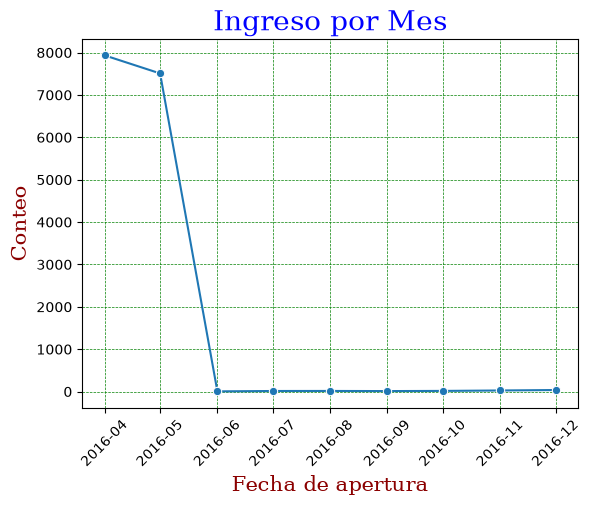

In [10]:
# Grafico de Lineas

plt.grid(color = 'green', linestyle = '--', linewidth = .5)     #Refeire a la malla

sns.lineplot(
    data=df_analysis_open,                                      #Base de datos fuente
    x="opened_at",                                              #Columna de datos para X
    y="count",                                                  #Columna de datos para Y
    marker="o"                                                  #Simbolo de los puntos
)

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Ingreso por Mes", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Fecha de apertura", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45)                                         #Para rotar el eje X
plt.ylabel("Conteo", fontdict = font2)                         #Titulo en Y


Como se logra evidenciar en la grafica anterior, se comprueba que la gran mayoria de los casos fueron ingresados en abril y en mayo. Este comportamiento se comrpueba en los graficos referente al SLA

# 5.5. Como fue la distribucion de los SLA en los diferentes trimestres y cual fue su cumplimiento

In [11]:
df_SLA_q2 = df_analysis_q2["made_sla"].value_counts().reset_index()
df_SLA_q2_norm = (df_analysis_q2["made_sla"].value_counts(normalize=True)*100).reset_index()
df_SLA_q3 = df_analysis_q3["made_sla"].value_counts().reset_index()
df_SLA_q3_norm = (df_analysis_q3["made_sla"].value_counts(normalize=True)*100).reset_index()
df_SLA_q4 = df_analysis_q4["made_sla"].value_counts().reset_index()
df_SLA_q4_norm = (df_analysis_q4["made_sla"].value_counts(normalize=True)*100).reset_index()

df_SLA = df_analysis["made_sla"].value_counts().reset_index()
df_SLA_norm =  (df_analysis["made_sla"].value_counts(normalize=True)*100).reset_index()


Text(0, 0.5, 'Porcentaje de casos %')

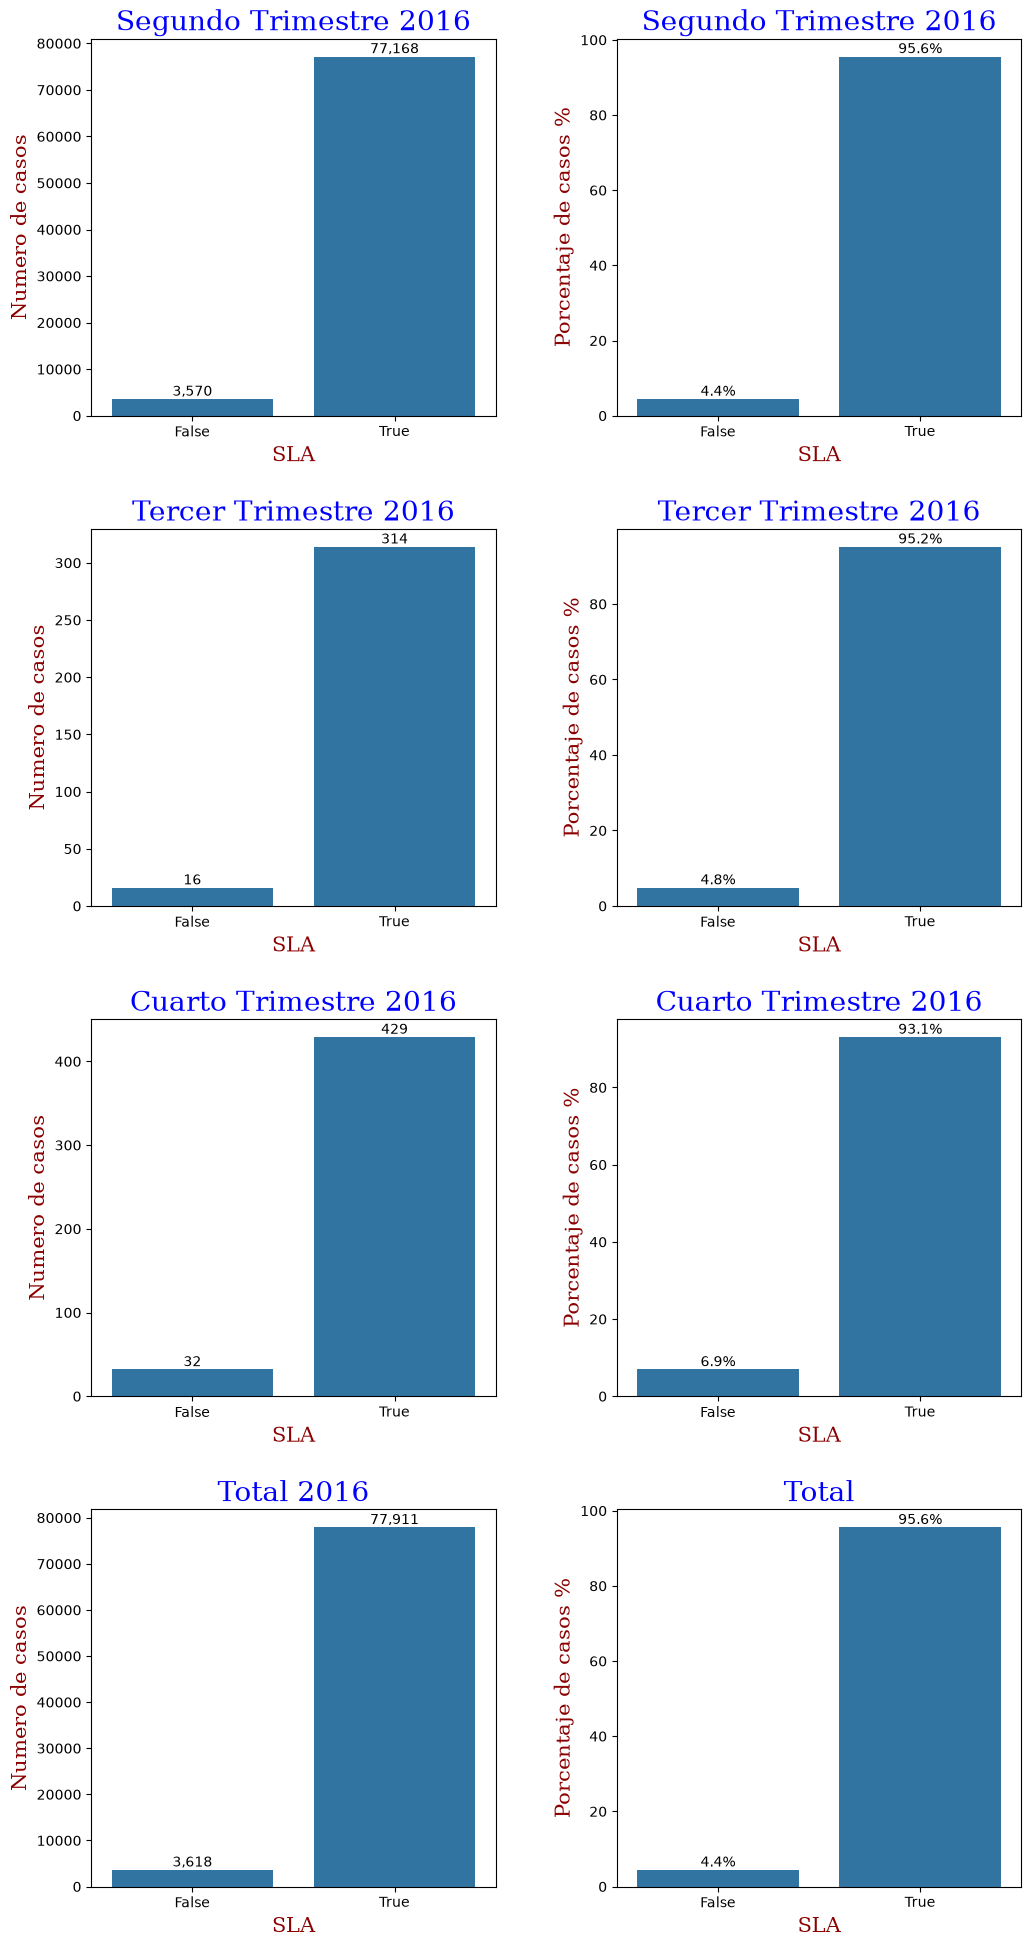

In [12]:
#Revisar porcentaje de CLA y grafica


# Grafico de barras

plt.figure(figsize=(12,24))                                      #indica tamaño de la figura

plt.subplots_adjust(
    wspace=0.3,
    hspace=0.3
)

# Segundo cuartil
plt.subplot(4,2,1)

ax = sns.barplot(
    data=df_SLA_q2,
    x="made_sla",
    y="count"
)
ax.bar_label(ax.containers[0],
    fmt='{:,.0f}')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Segundo Trimestre 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Numero de casos", fontdict = font2)                           #Titulo en X


plt.subplot(4,2,2)

ax = sns.barplot(
    data=df_SLA_q2_norm,
    x="made_sla",
    y="proportion"
)
ax.bar_label(ax.containers[0],
    fmt='%.1f%%')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Segundo Trimestre 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Porcentaje de casos %", fontdict = font2)                           #Titulo en X


# Tercer cuartil
plt.subplot(4,2,3)

ax = sns.barplot(
    data=df_SLA_q3,
    x="made_sla",
    y="count"
)
ax.bar_label(ax.containers[0],
    fmt='{:,.0f}')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Tercer Trimestre 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Numero de casos", fontdict = font2)                           #Titulo en X

plt.subplot(4,2,4)

ax = sns.barplot(
    data=df_SLA_q3_norm,
    x="made_sla",
    y="proportion"
)
ax.bar_label(ax.containers[0],
    fmt='%.1f%%')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Tercer Trimestre 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Porcentaje de casos %", fontdict = font2)                           #Titulo en X


# Cuarto cuartil
plt.subplot(4,2,5)

ax = sns.barplot(
    data=df_SLA_q4,
    x="made_sla",
    y="count"
)
ax.bar_label(ax.containers[0],
    fmt='{:,.0f}')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Cuarto Trimestre 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Numero de casos", fontdict = font2)                           #Titulo en X

plt.subplot(4,2,6)

ax = sns.barplot(
    data=df_SLA_q4_norm,
    x="made_sla",
    y="proportion"
)
ax.bar_label(ax.containers[0],
    fmt='%.1f%%')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Cuarto Trimestre 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Porcentaje de casos %", fontdict = font2)                           #Titulo en X


# Total
plt.subplot(4,2,7)

ax = sns.barplot(
    data=df_SLA,
    x="made_sla",
    y="count"
)
ax.bar_label(ax.containers[0],
    fmt='{:,.0f}')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Total 2016", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Numero de casos", fontdict = font2)                           #Titulo en X


plt.subplot(4,2,8)

ax = sns.barplot(
    data=df_SLA_norm,
    x="made_sla",
    y="proportion"
)
ax.bar_label(ax.containers[0],
    fmt='%.1f%%')

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Total", fontdict = font1)                 #Titulo del Grafico
plt.xlabel("SLA", fontdict = font2)                        #Titulo en Y
plt.ylabel("Porcentaje de casos %", fontdict = font2)                           #Titulo en X


De acuerdo a los datos revisados en las graficas previas, se encuentra que el segundo trimestre tiene la gran mayoria de los casos respecto al tercero y cuarto semestre. Por otro lado se logra evidenciar que generalmente la totalidad de los casos se ateiende con un SLA del 95.6% se atiende en buenos tiempos.

# 5.6. Cual fuel el metodo de contacto mas utilizado y como medirlo

In [13]:

df_last_type = df_analysis[["number","contact_type"]][df_analysis["active"]==True].loc[
    df_analysis[df_analysis["active"]==True].groupby("number")["sys_mod_count"].idxmax()] #se encuentra el ultimo dato de acuerdo a sys_mod_count

df_last_type_co = df_last_type["contact_type"].value_counts().reset_index()
df_last_type_co_norm = df_last_type["contact_type"].value_counts(normalize=True).reset_index()


Text(0, 0.5, 'Porcentaje de casos')

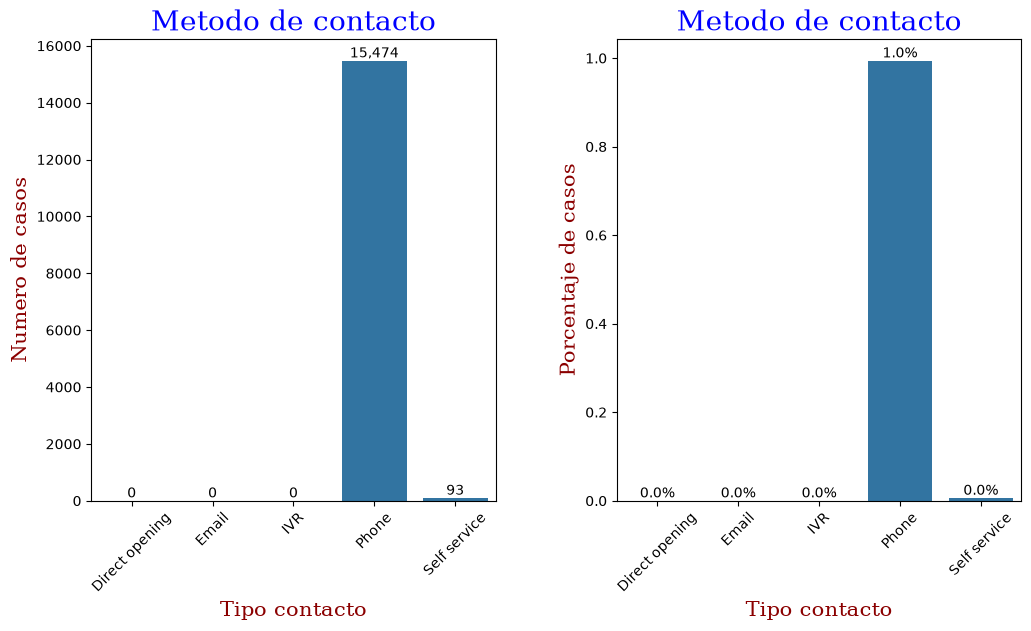

In [14]:
# Grafico de Barras para mostrar el estado actual de los casos


plt.figure(figsize=(12,6))                                      #indica tamaño de la figura

plt.subplots_adjust(
    wspace=0.3,
    hspace=0.3
)

# Grafico nominal
plt.subplot(1,2,1)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_type_co,						#Data frame
    x="contact_type",						#Refiere al eje X
    y="count"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='{:,.0f}')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Metodo de contacto", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Tipo contacto", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Numero de casos", fontdict = font2)                         #Titulo en Y

#Grafico porcentual
plt.subplot(1,2,2)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_type_co_norm,						#Data frame
    x="contact_type",						#Refiere al eje X
    y="proportion"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='%.1f%%')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Metodo de contacto", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Tipo contacto", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Porcentaje de casos", fontdict = font2)                         #Titulo en Y

Como se logra evidenciar en la grafica anterior el metodo mas utilizado para realizar una atencion de caso es el metodo telefonico, con un porcentaje del 100 %

# 5.7. Crear indicador de estado actual de casos y su grafico

In [15]:

df_last_state = df_analysis[["number","incident_state"]][df_analysis["active"]==True].loc[
    df_analysis[df_analysis["active"]==True].groupby("number")["sys_mod_count"].idxmax()] #se encuentra el ultimo dato de acuerdo a sys_mod_count

df_last_state_co = df_last_state["incident_state"].value_counts().reset_index()
df_last_state_co_norm = df_last_state["incident_state"].value_counts(normalize=True).reset_index()


Text(0, 0.5, 'Porcentaje de casos')

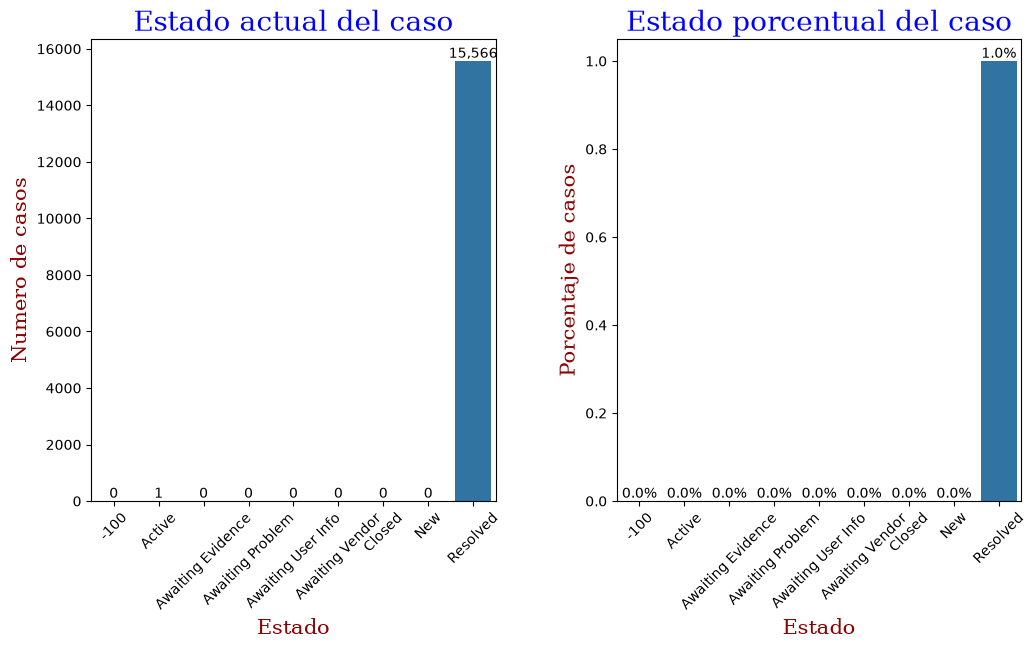

In [16]:
# Grafico de Barras para mostrar los tipos de contactos


plt.figure(figsize=(12,6))                                      #indica tamaño de la figura

plt.subplots_adjust(
    wspace=0.3,
    hspace=0.3
)

# Grafico nominal
plt.subplot(1,2,1)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_state_co,						#Data frame
    x="incident_state",						#Refiere al eje X
    y="count"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='{:,.0f}')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Estado actual del caso", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Estado", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Numero de casos", fontdict = font2)                         #Titulo en Y

#Grafico porcentual
plt.subplot(1,2,2)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_state_co_norm,						#Data frame
    x="incident_state",						#Refiere al eje X
    y="proportion"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='%.1f%%')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Estado porcentual del caso", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Estado", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Porcentaje de casos", fontdict = font2)                         #Titulo en Y

# 5.8. Relación entre impacto, urgencia y prioridad

In [17]:
df_last_priority = df_analysis[["number","impact","urgency","priority"]][df_analysis["active"]==True].loc[
    df_analysis[df_analysis["active"]==True].groupby("number")["sys_mod_count"].idxmax()]   #se encuentra el ultimo dato de acuerdo a sys_mod_count
                                                                                            #y se usa el estado activo en True porque es el que permite ver la realidad de los datos

df_last_pri_impact_co = df_last_priority["impact"].value_counts().reset_index()
df_last_pri_urgency_co = df_last_priority["urgency"].value_counts().reset_index()
df_last_pri_priority_co = df_last_priority["priority"].value_counts().reset_index()



Text(0, 0.5, 'Numero de casos')

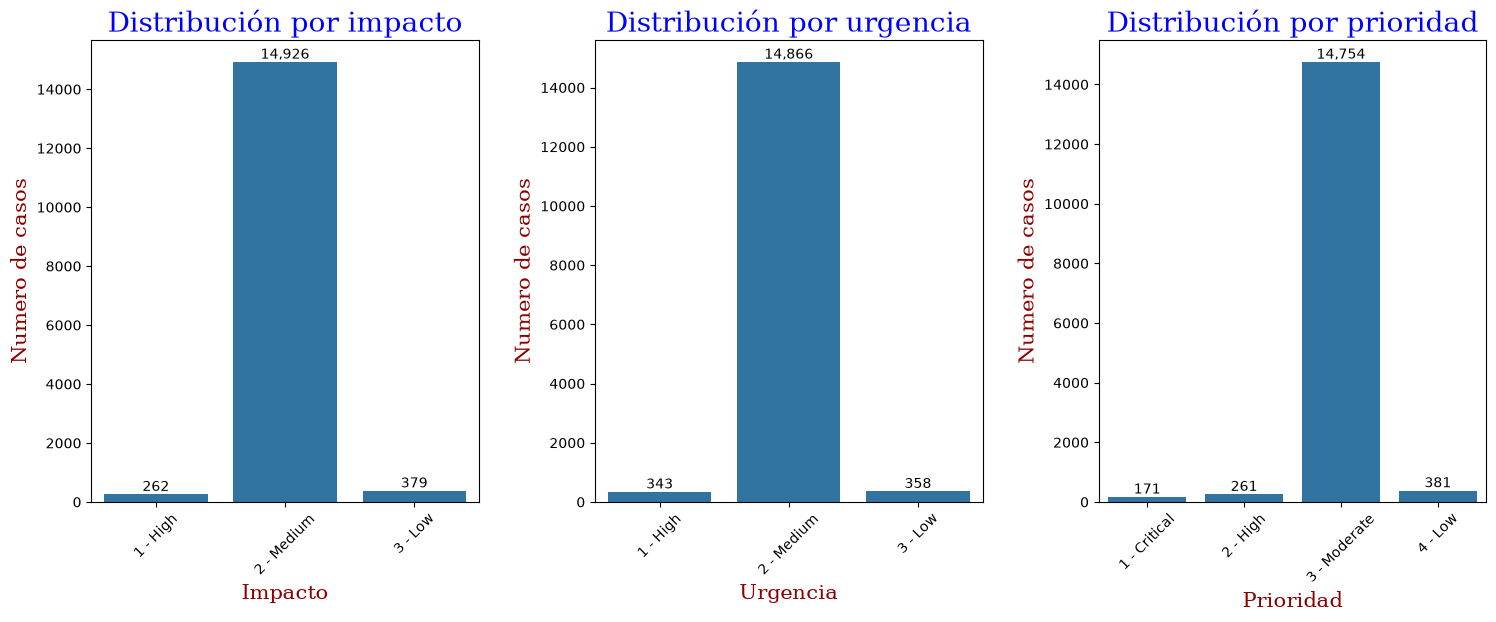

In [18]:
# Grafico de Barras para mostrar el estado actual de los casos


plt.figure(figsize=(18,6))                                      #indica tamaño de la figura

plt.subplots_adjust(
    wspace=0.3,
    hspace=0.3
)

# Grafico nominal impacto
plt.subplot(1,3,1)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_pri_impact_co,						#Data frame
    x="impact",						#Refiere al eje X
    y="count"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='{:,.0f}')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Distribución por impacto", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Impacto", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Numero de casos", fontdict = font2)                         #Titulo en Y

#Grafico nominal urgencia
plt.subplot(1,3,2)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_pri_urgency_co,						#Data frame
    x="urgency",						#Refiere al eje X
    y="count"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='{:,.0f}')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Distribución por urgencia", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Urgencia", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Numero de casos", fontdict = font2)                         #Titulo en Y


#Grafico nominal prioridad
plt.subplot(1,3,3)						#indica la altura, el ancho de los subplot, y el tercero es la ubicacion


ax = sns.barplot(						#Grafico de barras
    data=df_last_pri_priority_co,						#Data frame
    x="priority",						#Refiere al eje X
    y="count"							#Refiere al eje Y
)

ax.bar_label(ax.containers[0],					#Valor del grafico
    fmt='{:,.0f}')						#Formato de los valores

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Distribución por prioridad", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("Prioridad", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45) 
plt.ylabel("Numero de casos", fontdict = font2)                         #Titulo en Y

Las distribuciones analizadas muestran que la mayoría de los incidentes se concentra en niveles medios de impacto, urgencia y prioridad. Los casos clasificados en niveles altos o bajos representan una proporción considerablemente menor dentro del conjunto de datos analizado.

# 6. Hallazgos Principales

## Hallazgo 1: Reapertura de incidentes

Solo el 0,9 % de los incidentes requirió al menos una reapertura, lo que indica que este comportamiento fue poco frecuente dentro del proceso analizado.

## Hallazgo 2: Reasignación de incidentes

Aproximadamente el 39,76 % de los incidentes fue reasignado al menos una vez, lo que evidencia que la transferencia de casos representa una parte relevante de la operación.

## Hallazgo 3: Complejidad operativa

Cada incidente registró, en promedio, 5,9 actualizaciones durante su ciclo observado, lo que sugiere que la gestión de los casos requiere múltiples interacciones y cambios antes de alcanzar su resolución.

## Hallazgo 4: Cumplimiento de SLA

El cumplimiento de los acuerdos de nivel de servicio fue elevado durante el periodo evaluado. Dependiendo del nivel de análisis utilizado (eventos o incidentes consolidados), el indicador presenta valores superiores al 95 %.

## Hallazgo 5: Perfil de los incidentes

La mayoría de los incidentes se concentró en niveles medios de impacto, urgencia y prioridad, lo que sugiere una carga operativa compuesta principalmente por requerimientos de complejidad moderada.

## Hallazgo 6: Concentracionde apertura de casos

La creación de nuevos incidentes se concentra de forma extraordinaria durante el segundo trimestre de 2016. Los incidentes creados durante el tercer y cuarto trimestre representan una proporción muy reducida del total analizado. Este comportamiento corresponde a la distribución observada en la fuente de datos original y condiciona la interpretación de las tendencias temporales.

# 7. Limitaciones del Análisis

- El conjunto de datos está estructurado como un registro de eventos, por lo que un incidente puede aparecer múltiples veces.
- El periodo analizado se definió utilizando la fecha de apertura del incidente.
- Los identificadores se encuentran anonimizados y no cuentan con tablas descriptivas externas.
- La distribución temporal muestra una concentración importante de aperturas durante abril y mayo de 2016.
- El indicador sys_mod_count representa modificaciones generales del incidente y no exclusivamente cambios de estado.

# 8. Exportación del conjunto de datos para Power BI

In [19]:
# Crear conjunto de datos para Power BI


#Se realiza copiado de datos totales depurados

df_powerbi = df_analysis.copy()
df_powerbi.to_csv(								#Creacion de archivo CSV

    "../Data/Processed/incident_powerbi.csv",
    index=False,								#El comando indica que no se añade el index
    
)


print("Archivo exportado correctamente.")


#Se realiza copiado de datos unicos en referencia al ultimo cambio y solo los casos activos
df_powerbi_s = df_analysis[df_analysis["active"]==True].loc[
    df_analysis[df_analysis["active"]==True].groupby("number")["sys_mod_count"].idxmax()].copy()   #se encuentra el ultimo dato de acuerdo a sys_mod_count


df_powerbi_s.to_csv(								#Creacion de archivo CSV

    "../Data/Processed/incident_powerbi_single.csv",
    index=False,								#El comando indica que no se añade el index
    
)


print("Archivo exportado correctamente.")


#Conjunto de datos exportado
#Se exportó una versión procesada y filtrada del conjunto de datos,
#correspondiente al periodo comprendido entre abril y diciembre de 2016.
#Este archivo constituye la fuente principal para la construcción del dashboard en Power BI.

Archivo exportado correctamente.
Archivo exportado correctamente.
